# Chapitre 9 - Cours 6 : méthodes formelles et tests aléatoires

Les cours précédents ont montré combien de choses peuvent mal tourner : messages perdus
ou retardés, pauses, horloges fausses, nœuds amnésiques. Comment savoir qu'un algorithme
et, surtout, son implémentation respectent leurs propriétés de sûreté **dans tous les
cas** ? Ce notebook, consacré à une section nouvelle de la 2e édition, construit un petit
**model checker** exhaustif, pratique l'**injection de fautes** et la **simulation
déterministe** sur le protocole de bail du cours 4. Il couvre la section *Formal Methods
and Randomized Testing* (*Model checking and specification languages*, *Fault
injection*, *Deterministic simulation testing*, encadré *The Power of Determinism*).

**Plan.**

1. Pourquoi tester à la main ne suffit pas : l'explosion des entrelacements.
2. Un model checker en 60 lignes.
3. L'injection de fautes.
4. La simulation déterministe.
5. La puissance du déterminisme.

In [1]:
import os
import subprocess
import sys
import time
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia import distsys_verif as dv
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 110)

## 1. Pourquoi tester à la main ne suffit pas (section *Formal Methods and Randomized Testing*)

À cause de la concurrence, des pannes partielles et des délais réseau, un système
distribué a un nombre **gigantesque** d'états possibles. Il faut que les propriétés
tiennent dans **chacun**, sans oublier de cas limite. Comptons seulement les ordres
possibles d'exécution (entrelacements) de $k$ processus de $s$ étapes chacun, sans même
ajouter de pannes : $\frac{(ks)!}{(s!)^k}$.

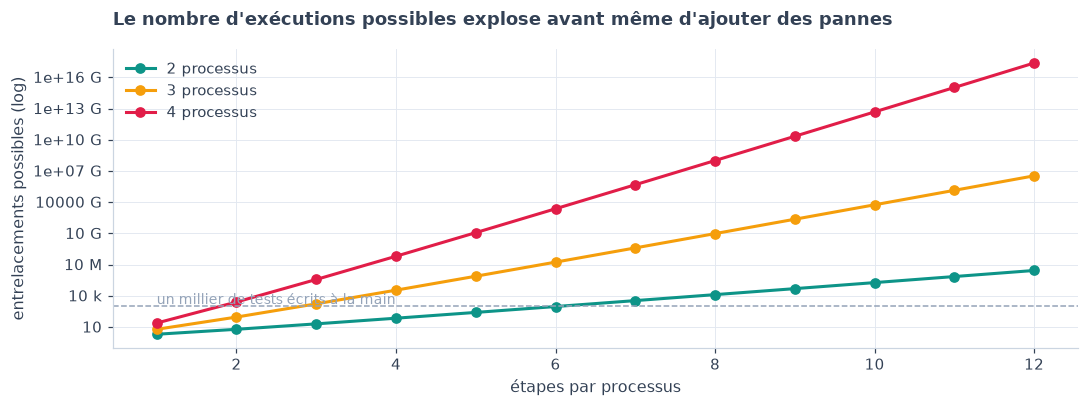

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.8))
s_ = np.arange(1, 13)
for k, c in [(2, TEAL), (3, AMBER), (4, ROSE)]:
    ax.semilogy(s_, [factorial(k * s) / factorial(s) ** k for s in s_], "o-", color=c, label=f"{k} processus")
ax.axhline(1e3, color=GRAY, ls="--", lw=1); ax.text(1, 1.6e3, "un millier de tests écrits à la main", fontsize=9, color=GRAY)
plain_log_axis(ax, "y")
ax.set_xlabel("étapes par processus"); ax.set_ylabel("entrelacements possibles (log)")
ax.set_title("Le nombre d'exécutions possibles explose avant même d'ajouter des pannes")
ax.legend()
plt.tight_layout(); plt.show()

Trois processus de dix étapes ont déjà $5{,}5 \times 10^{12}$ entrelacements. Le livre
décrit deux familles de réponses, à **combiner** :

- la **vérification formelle** : décrire l'algorithme mathématiquement et prouver qu'il
  satisfait ses propriétés dans toutes les situations du modèle de système. Prouver
  l'algorithme ne garantit pas que l'implémentation soit correcte, mais l'analyse révèle
  des problèmes qui resteraient cachés longtemps en production, jusqu'au jour où une
  hypothèse (de temps, par exemple) est mise en défaut ;
- les **tests aléatoires** : tests fondés sur des propriétés, fuzzing, **simulation
  déterministe**, qui explorent une grande variété de situations. Amazon Web Services,
  FoundationDB ou TigerBeetle combinent ces techniques avec succès.

> **À retenir.** L'espace des exécutions d'un système distribué est trop grand pour des
> tests écrits à la main. On combine raisonnement formel (preuve, model checking) et
> exploration aléatoire massive.